# Employee attrition: a classification study

**GCI final project · The University of Tokyo, Matsuo-Iwasawa Laboratory**

This project explores a course-modified HR dataset and compares a few models for
classifying employee attrition. The question is: **can these models identify
attrition cases more usefully than a simple baseline?**

I focus on three things: understanding the data, evaluating models without
sharing fitted preprocessing across splits, and explaining what the results do
and do not show. This is a student modelling exercise, not a validated tool for
making decisions about employees.

**Contents:** setup and data checks → validation design → exploratory analysis →
features and preprocessing → model comparison → evaluation → interpretation.

This revised analysis replaces the earlier notebook results. The PDF in this
repository is the original submitted presentation; its features and scores
describe the earlier version.

## 1. Setup

Run the cells in order from a fresh kernel. Install `requirements.txt` first (see
the README). The CSV can be beside this notebook, or in `FINAL PROJECT` when the
notebook is opened from the parent course folder. In Colab, upload the CSV to the
working directory or clone the repository first; Google Drive is not required.

The notebook saves figures to `assets/` and small result tables to `results/`.
The random seed and model settings are fixed to make reruns comparable.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

SEED = 42
N_SPLITS = 5
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})

packages = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "xgboost"]
environment = {name: version(name) for name in packages}
environment["python"] = platform.python_version()
display(pd.Series(environment, name="Version").to_frame())

,Version
numpy,2.2.6
pandas,2.2.3
matplotlib,3.10.7
seaborn,0.13.2
scikit-learn,1.7.2
xgboost,3.0.5
python,3.13.3


In [2]:
CSV_NAME = "data._finalprojectcsv.csv"
candidates = [Path.cwd() / CSV_NAME, Path.cwd() / "FINAL PROJECT" / CSV_NAME]
DATA_PATH = next((path for path in candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Place {CSV_NAME} beside the notebook, or run from the course folder."
    )

ROOT = DATA_PATH.parent
ASSETS = ROOT / "assets"
RESULTS = ROOT / "results"
ASSETS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH)

assert df.columns.is_unique, "Column names must be unique."
assert df["Attrition"].isin(["Yes", "No"]).all(), "Unexpected target labels."
assert df[["EmployeeNumber", "Year"]].notna().all().all(), "Missing split keys."

print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {DATA_PATH.name}.")
display(df.head())

Loaded 1,470 rows and 44 columns from data._finalprojectcsv.csv.


,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,...,RemoteWork,MonthlyIncome,StressRating,WelfareBenefits,InHouseFacility,ExternalFacility,ExtendedLeave,FlexibleWork,StressSelfReported,Year
0,41,Yes,Travel_Rarely,Sales,1,2,Life Sciences,1,1,2,...,1,5224,4,1,0,0,0,0,1,2023
1,49,No,Travel_Frequently,Research & Development,8,1,Life Sciences,1,2,3,...,3,6863,2,4,1,0,0,1,1,2023
2,37,Yes,Travel_Rarely,Research & Development,2,2,Other,1,4,4,...,2,7612,3,2,1,0,0,0,1,2023
3,33,No,Travel_Frequently,Research & Development,3,4,Life Sciences,1,5,4,...,2,11245,1,4,1,1,1,1,1,2023
4,27,No,Travel_Rarely,Research & Development,2,1,Medical,1,7,1,...,2,3029,3,2,0,0,0,0,3,2023


## 2. Data checks and validation design

The course describes this as a modified IBM HR dataset. It contains the usual
demographic and job variables plus course-specific fields such as stress,
facilities, and `Year`. I do not have a full account of how these fields or the
attrition labels were constructed. The rows should not be presented as verified
records of IBM's current workforce.

Before modelling, I check missing values, duplicate rows, repeated identifiers,
and the year labels. An identifier repeated across years is different from a
completely duplicated row.

In [3]:
audit = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Missing cells": int(df.isna().sum().sum()),
    "Duplicate complete rows": int(df.duplicated().sum()),
    "Unique employee IDs": df["EmployeeNumber"].nunique(),
    "IDs appearing more than once": int(df.groupby("EmployeeNumber").size().gt(1).sum()),
}, name="Value")
display(audit.to_frame())
display(pd.crosstab(df["Year"], df["Attrition"]).rename_axis(columns="Attrition"))
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
}))

,Value
Rows,1470
Columns,44
Missing cells,0
Duplicate complete rows,0
Unique employee IDs,1442
IDs appearing more than once,28


Attrition,No,Yes
Year,,
2023,988,188
2024,244,50


,dtype,missing,unique
Age,int64,0,43
Attrition,object,0,2
BusinessTravel,object,0,3
Department,object,0,3
DistanceFromHome,int64,0,29
Education,int64,0,5
EducationField,object,0,6
EmployeeCount,int64,0,1
EmployeeNumber,int64,0,1442
EnvironmentSatisfaction,int64,0,4


### Split before exploratory modelling

I use rows labelled **2023 for development** and rows labelled **2024 for the
holdout**. For the question of performance on previously unseen employees, I
also remove 2023 rows whose employee IDs occur in the 2024 holdout. This
conservative choice avoids sharing an ID across the two sets.

The split uses the supplied year labels; it does not prove that the dataset is a
real longitudinal sample or that every feature was available before attrition.
With only one development year, cross-validation below measures variation
within that year rather than performance across several future periods.

All model selection, preprocessing fitting, and threshold selection use only
development data. The holdout is used after those decisions are fixed. Earlier
versions of this project already examined this dataset, so this revised holdout
is not a new external validation sample.

In [4]:
assert set(df["Year"].unique()) == {2023, 2024}, "Review the split if years change."
holdout = df.loc[df["Year"].eq(2024)].copy()
holdout_ids = set(holdout["EmployeeNumber"])
overlap = df["Year"].eq(2023) & df["EmployeeNumber"].isin(holdout_ids)
development = df.loc[df["Year"].eq(2023) & ~overlap].copy()

assert set(development["EmployeeNumber"]).isdisjoint(holdout_ids)
assert development["EmployeeNumber"].is_unique
assert holdout["EmployeeNumber"].is_unique
assert development["Year"].max() < holdout["Year"].min()

split_summary = pd.DataFrame({
    "split": ["Development (2023)", "Holdout (2024)"],
    "rows": [len(development), len(holdout)],
    "attrition_cases": [development["Attrition"].eq("Yes").sum(), holdout["Attrition"].eq("Yes").sum()],
})
split_summary["attrition_rate"] = split_summary["attrition_cases"] / split_summary["rows"]
print(f"Excluded {overlap.sum()} earlier-year rows with holdout employee IDs.")
display(split_summary.round(4))

Excluded 28 earlier-year rows with holdout employee IDs.


,split,rows,attrition_cases,attrition_rate
0,Development (2023),1148,188,0.1638
1,Holdout (2024),294,50,0.1701


## 3. Exploratory analysis on development data

First, I look at the target balance. If most employees have a `No` label,
predicting `No` for everyone can produce high accuracy while finding no attrition
cases. That is why the evaluation includes a baseline and minority-class metrics.

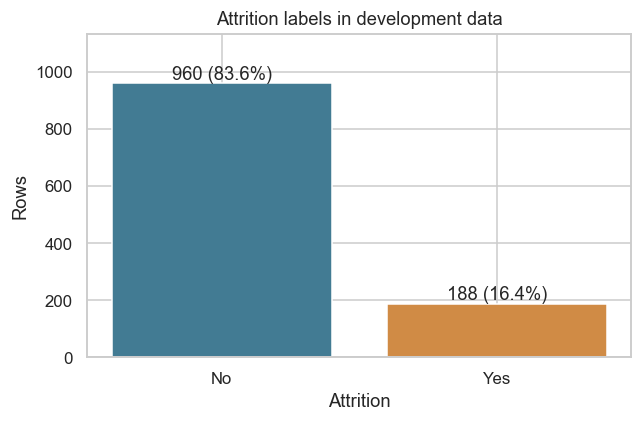

In [5]:
counts = development["Attrition"].value_counts().reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=["#427b93", "#d08b45"])
ax.bar_label(bars, labels=[f"{n} ({n / counts.sum():.1%})" for n in counts])
ax.set(title="Attrition labels in development data", xlabel="Attrition", ylabel="Rows")
ax.set_ylim(0, counts.max() * 1.18)
fig.tight_layout()
fig.savefig(ASSETS / "target-attrition-distribution.png")
plt.show()

### Compare group rates and distributions

Raw counts can be misleading when departments have different sizes. The table
below includes group sizes alongside attrition rates. Small groups can have
unstable rates. The plots show associations in this sample; they do not show
that changing a particular variable would prevent an employee from leaving.

,employees,attrition_cases,attrition_rate
Department,,,
Human Resources,48,11,0.229
Sales,357,75,0.210
Research & Development,743,102,0.137


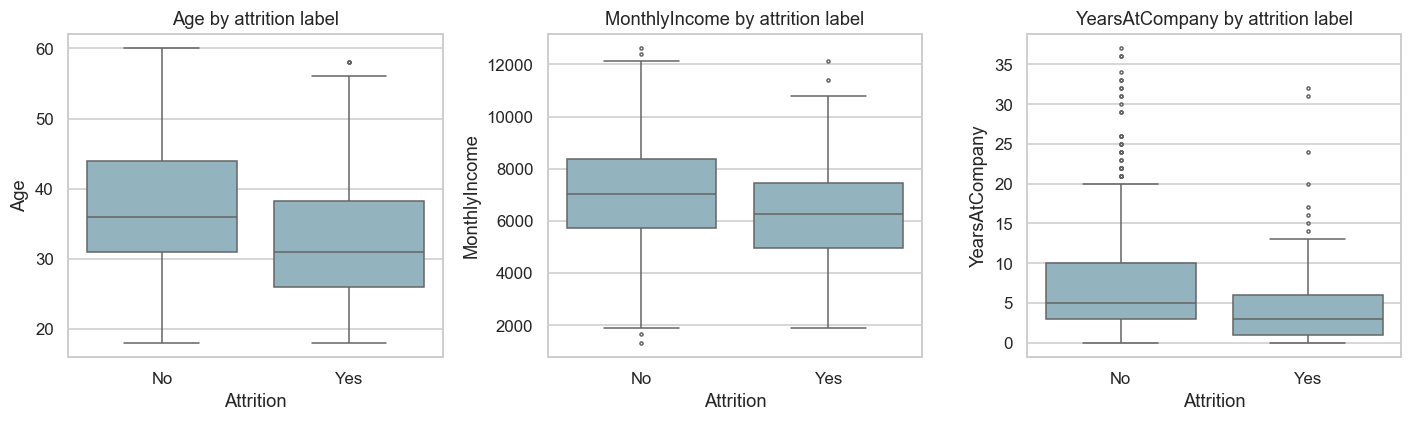

In [6]:
eda = development.assign(AttritionFlag=development["Attrition"].eq("Yes").astype(int))
department_summary = (
    eda.groupby("Department")["AttritionFlag"]
    .agg(employees="size", attrition_cases="sum", attrition_rate="mean")
    .sort_values("attrition_rate", ascending=False)
)
display(department_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, column in zip(axes, ["Age", "MonthlyIncome", "YearsAtCompany"]):
    sns.boxplot(data=development, x="Attrition", y=column, order=["No", "Yes"], ax=ax,
                color="#8cb6c5", fliersize=2)
    ax.set_title(f"{column} by attrition label")
fig.tight_layout()
fig.savefig(ASSETS / "eda-distributions.png")
plt.show()

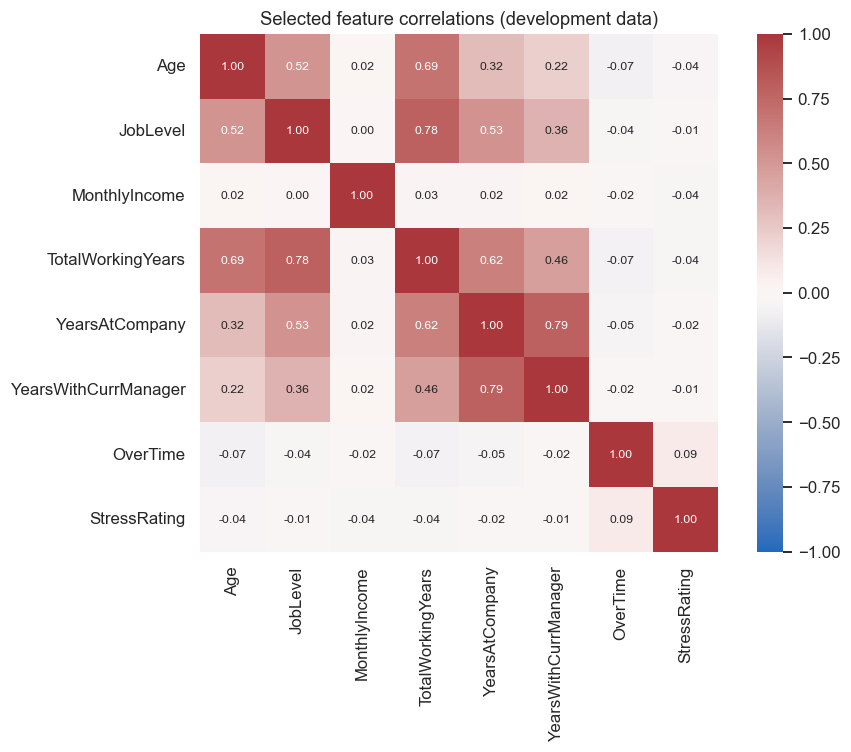

In [7]:
correlation_columns = [
    "Age", "JobLevel", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
    "YearsWithCurrManager", "OverTime", "StressRating",
]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(development[correlation_columns].corr(), annot=True, fmt=".2f",
            cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax,
            annot_kws={"size": 8})
ax.set_title("Selected feature correlations (development data)")
fig.tight_layout()
fig.savefig(ASSETS / "correlation-heatmap.png")
plt.show()

The heatmap shows positive correlations among age, seniority, and tenure.
`JobLevel` and `TotalWorkingYears`, and `YearsAtCompany` and
`YearsWithCurrManager`, are strongly correlated in this sample.
`MonthlyIncome` has weak linear correlations with the selected variables
in this course-modified dataset. This matters when interpreting feature importance: a model can
share a signal across correlated predictors. I keep this small exploratory
selection separate from automatic feature selection and do not remove features
based on the holdout results.

## 4. Features and preprocessing

`Attrition` is mapped to 0/1. `EmployeeNumber` and `Year` define the split and are
excluded as predictors. Columns constant in development data are also removed.

I retain four simple features from the original project: income per job level,
the fraction of company tenure spent with the current manager, and two numeric
interactions. These are hypotheses about useful representations, not established
causes of attrition. A ratio with a zero denominator is left missing and imputed
using training data, rather than divided by an arbitrary tiny number.

In [8]:
constant_columns = [
    col for col in development.columns
    if col not in ["Attrition", "EmployeeNumber", "Year"]
    and development[col].nunique(dropna=False) <= 1
]
excluded_columns = ["Attrition", "EmployeeNumber", "Year"] + constant_columns
X_train = development.drop(columns=excluded_columns)
y_train = development["Attrition"].map({"No": 0, "Yes": 1})
X_test = holdout.drop(columns=excluded_columns)
y_test = holdout["Attrition"].map({"No": 0, "Yes": 1})

assert "Attrition" not in X_train and "EmployeeNumber" not in X_train and "Year" not in X_train
assert X_train.columns.equals(X_test.columns)
assert y_train.value_counts().min() >= N_SPLITS
print("Constant columns removed:", constant_columns)
print("Raw predictor count:", X_train.shape[1])


def add_features(frame):
    '''Create row-level features without learning anything from other rows.'''
    result = frame.copy()
    result["IncomePerJobLevel"] = result["MonthlyIncome"] / result["JobLevel"].replace(0, np.nan)
    result["YearsWithManagerRatio"] = result["YearsWithCurrManager"] / result["YearsAtCompany"].replace(0, np.nan)
    result["Age_JobLevel_Interaction"] = result["Age"] * result["JobLevel"]
    result["TotalWorkingYears_MonthlyIncome_Interaction"] = result["TotalWorkingYears"] * result["MonthlyIncome"]
    return result


display(add_features(X_train).filter(regex="Ratio|PerJobLevel|Interaction").head())

Constant columns removed: ['EmployeeCount', 'Over18', 'StandardHours']
Raw predictor count: 38


,IncomePerJobLevel,YearsWithManagerRatio,Age_JobLevel_Interaction,TotalWorkingYears_MonthlyIncome_Interaction
0,2612.0,0.833333,82,41792
1,3431.5,0.700000,98,68630
2,7612.0,NaN,37,53284
3,11245.0,0.000000,33,89960
4,3029.0,1.000000,27,18174


### Fit transformations inside each training fold

The pipeline adds the row-level features, imputes numeric values with the median,
scales numeric features, and one-hot encodes categorical features. Imputation,
scaling, and category discovery are fitted only on the training portion of each
fold. An unseen category at prediction time is handled without refitting.

Scaling is useful for logistic regression. The tree models do not need it, but
using the same preprocessing keeps this comparison straightforward. Ordinal
survey scores are treated as numeric, which is a simplifying assumption for
the linear model.

In [9]:
def make_model_pipeline(estimator):
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ("numeric", numeric, make_column_selector(dtype_include=np.number)),
        ("categorical", categorical, make_column_selector(dtype_include=object)),
    ])
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocess", preprocess),
        ("model", clone(estimator)),
    ])

## 5. Compare models on development data

I compare a dummy baseline, logistic regression, random forest, and XGBoost.
The dummy returns the training class proportions; at a threshold of 0.5 it
predicts the majority class. Random forest provides a bagging comparison with
XGBoost's boosting. Logistic regression and random forest use balanced class
weights; XGBoost uses its default unweighted objective.

The settings below are fixed starting choices, not the result of an extensive
search. I use the same five stratified folds for every model. Employee IDs are
unique within development data, so a row-level split does not repeat an ID
across these folds.

**Primary selection metric: average precision (AP)**, which summarises the
precision-recall ranking and is useful here because positives are uncommon.
ROC AUC is a second ranking metric. Precision, recall, and F1 below use a 0.5
threshold. Accuracy is reported for context, not for model selection. Fold
standard deviations describe variability; they are not confidence intervals.

In [10]:
models = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(
        C=1.0, class_weight="balanced", solver="liblinear", max_iter=2000, random_state=SEED
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=200, max_depth=6, min_samples_leaf=5,
        class_weight="balanced", random_state=SEED, n_jobs=2
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, objective="binary:logistic",
        eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=2
    ),
}


def evaluate_scores(actual, probabilities, threshold=0.5):
    predicted = (np.asarray(probabilities) >= threshold).astype(int)
    return {
        "average_precision": average_precision_score(actual, probabilities),
        "roc_auc": roc_auc_score(actual, probabilities),
        "accuracy": accuracy_score(actual, predicted),
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "f1": f1_score(actual, predicted, zero_division=0),
    }


cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))
cv_rows = []
oof_probabilities = {}

for name, estimator in models.items():
    oof = np.full(len(X_train), np.nan)
    for fold, (fit_idx, validation_idx) in enumerate(folds, start=1):
        assert set(fit_idx).isdisjoint(validation_idx)
        pipeline = make_model_pipeline(estimator)
        pipeline.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        probabilities = pipeline.predict_proba(X_train.iloc[validation_idx])[:, 1]
        oof[validation_idx] = probabilities
        cv_rows.append({"model": name, "fold": fold,
                        **evaluate_scores(y_train.iloc[validation_idx], probabilities)})
    assert np.isfinite(oof).all()
    oof_probabilities[name] = oof
    print(f"Finished {name}.")

cv_results = pd.DataFrame(cv_rows)
metric_columns = ["average_precision", "roc_auc", "accuracy", "precision", "recall", "f1"]
cv_summary = cv_results.groupby("model")[metric_columns].agg(["mean", "std"])
cv_summary.columns = [f"{metric}_{stat}" for metric, stat in cv_summary.columns]
cv_summary = cv_summary.sort_values("average_precision_mean", ascending=False)
display(cv_summary.round(4))

Finished Dummy.


Finished Logistic regression.


Finished Random forest.


Finished XGBoost.


,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
model,,,,,,,,,,,,
XGBoost,0.6197,0.0911,0.8413,0.0457,0.8676,0.0156,0.7354,0.1402,0.3191,0.0561,0.4400,0.0626
Logistic regression,0.5934,0.0308,0.8350,0.0363,0.7779,0.0194,0.4000,0.0380,0.7232,0.0965,0.5148,0.0554
Random forest,0.5674,0.1219,0.8081,0.0399,0.8554,0.0398,0.5691,0.1376,0.5060,0.1184,0.5345,0.1241
Dummy,0.1638,0.0020,0.5000,0.0000,0.8362,0.0020,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### Choose a classification threshold using out-of-fold predictions

I select the highest mean-AP model, then compare a small, fixed grid of
thresholds using its development out-of-fold predictions. Each row's prediction
comes from a model trained without that row. I choose the threshold with the
highest F1; ties prefer the higher threshold.

This is an illustrative precision-recall trade-off, not a measured business
optimum. A real decision would need intervention costs and capacity. The same
development folds support model and threshold selection, so their scores are
selection evidence, not an unbiased estimate of the entire selection process.
The chosen threshold is fixed before evaluating the holdout.

Selected model: XGBoost
Development-selected threshold: 0.30


,threshold,precision,recall,f1
0,0.10,0.330,0.793,0.466
1,0.15,0.409,0.739,0.527
2,0.20,0.465,0.681,0.553
3,0.25,0.522,0.628,0.570
4,0.30,0.596,0.564,0.579
5,0.35,0.627,0.500,0.556
6,0.40,0.672,0.457,0.544
7,0.45,0.688,0.399,0.505
8,0.50,0.714,0.319,0.441
9,0.55,0.704,0.266,0.386


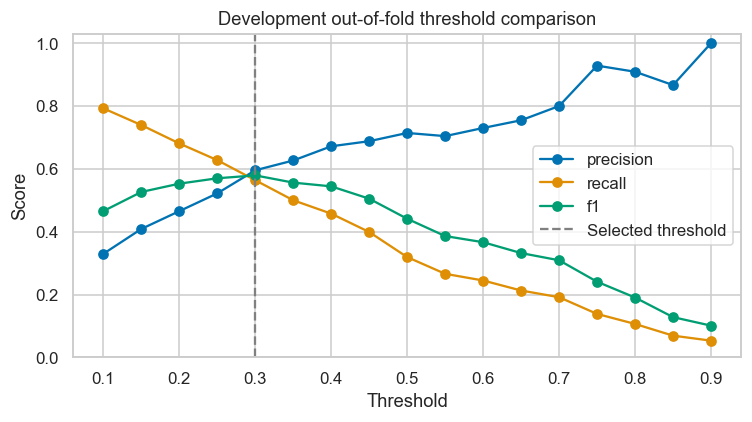

In [11]:
best_name = cv_summary.index[0]
threshold_rows = []
for threshold in np.round(np.linspace(0.10, 0.90, 17), 2):
    threshold_rows.append({"threshold": float(threshold),
                           **evaluate_scores(y_train, oof_probabilities[best_name], threshold)})
threshold_results = pd.DataFrame(threshold_rows)
chosen_threshold = float(
    threshold_results.sort_values(["f1", "threshold"], ascending=[False, False]).iloc[0]["threshold"]
)
print(f"Selected model: {best_name}")
print(f"Development-selected threshold: {chosen_threshold:.2f}")
display(threshold_results[["threshold", "precision", "recall", "f1"]].round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for metric in ["precision", "recall", "f1"]:
    ax.plot(threshold_results["threshold"], threshold_results[metric], marker="o", label=metric)
ax.axvline(chosen_threshold, color="grey", linestyle="--", label="Selected threshold")
ax.set(xlabel="Threshold", ylabel="Score", title="Development out-of-fold threshold comparison", ylim=(0, 1.03))
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "threshold-comparison.png")
plt.show()

## 6. Evaluate the fixed model on the holdout

I now fit the selected pipeline on all development rows and evaluate it on the
2024 holdout. The table includes the dummy, the selected model at 0.5, and the
same model at the development-selected threshold. Showing both thresholds makes
the trade-off visible; I do not choose between them using the holdout scores.

The prediction scores are used for ranking. They have not been calibrated, so
a score such as 0.7 should not be presented as a verified 70% probability of an
employee leaving.

,threshold,average_precision,roc_auc,accuracy,precision,recall,f1
setting,,,,,,,
Dummy at 0.50,0.5,0.1701,0.5000,0.8299,0.0000,0.00,0.0000
XGBoost at 0.50,0.5,0.5791,0.8034,0.8605,0.8000,0.24,0.3692
XGBoost at selected threshold,0.3,0.5791,0.8034,0.8605,0.6286,0.44,0.5176


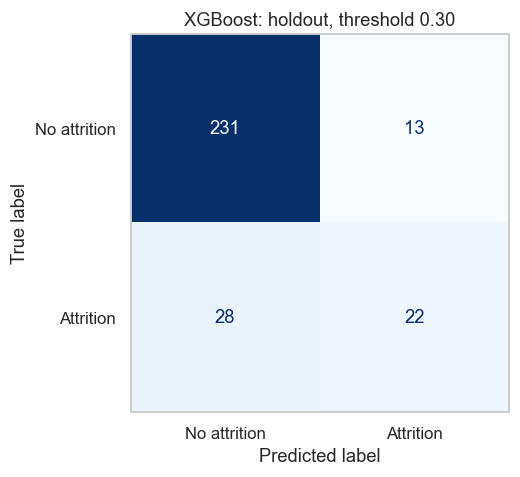

At the selected threshold, the model identifies **22 of 50** attrition cases and misses **28**. It flags **13** non-attrition cases incorrectly. The majority-class baseline has **83.0%** accuracy despite identifying no attrition cases.

In [12]:
best_model = make_model_pipeline(models[best_name])
best_model.fit(X_train, y_train)
test_probabilities = best_model.predict_proba(X_test)[:, 1]

baseline = make_model_pipeline(models["Dummy"])
baseline.fit(X_train, y_train)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame([
    {"setting": "Dummy at 0.50", "threshold": 0.5,
     **evaluate_scores(y_test, baseline_probabilities)},
    {"setting": f"{best_name} at 0.50", "threshold": 0.5,
     **evaluate_scores(y_test, test_probabilities)},
    {"setting": f"{best_name} at selected threshold", "threshold": chosen_threshold,
     **evaluate_scores(y_test, test_probabilities, chosen_threshold)},
]).set_index("setting")
display(test_results.round(4))

test_predictions = (test_probabilities >= chosen_threshold).astype(int)
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = (int(value) for value in cm.ravel())
assert cm.sum() == len(y_test)
assert np.isfinite(test_probabilities).all()
assert ((test_probabilities >= 0) & (test_probabilities <= 1)).all()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["No attrition", "Attrition"]).plot(
    ax=ax, colorbar=False, cmap="Blues"
)
ax.set_title(f"{best_name}: holdout, threshold {chosen_threshold:.2f}")
ax.grid(False)
fig.tight_layout()
fig.savefig(ASSETS / "confusion-matrix.png")
plt.show()

display(Markdown(
    f"At the selected threshold, the model identifies **{tp} of {tp + fn}** attrition cases "
    f"and misses **{fn}**. It flags **{fp}** non-attrition cases incorrectly. "
    f"The majority-class baseline has **{accuracy_score(y_test, np.zeros(len(y_test))):.1%}** "
    "accuracy despite identifying no attrition cases."
))

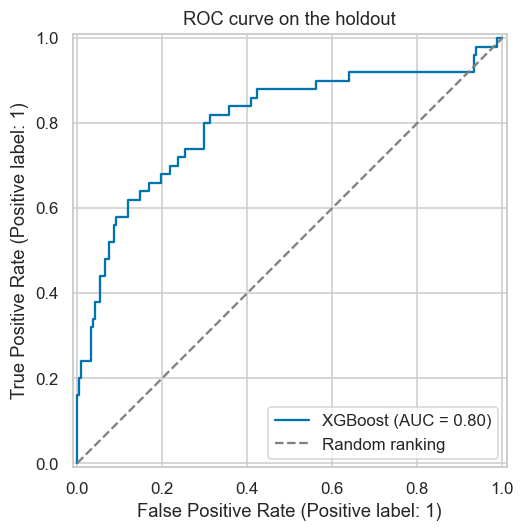

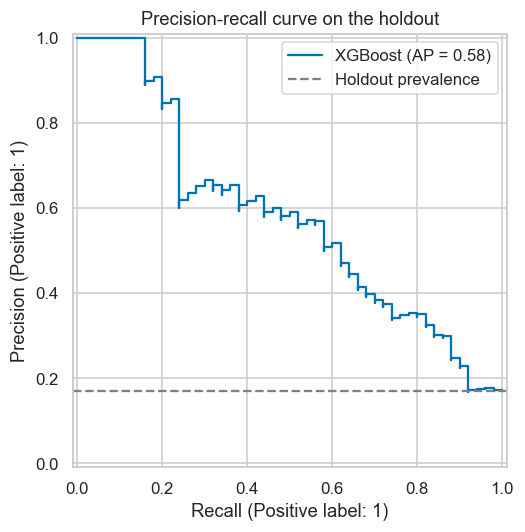

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, test_probabilities, name=best_name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random ranking")
ax.set_title("ROC curve on the holdout")
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "roc-curve.png")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, name=best_name, ax=ax)
ax.axhline(y_test.mean(), linestyle="--", color="grey", label="Holdout prevalence")
ax.set_title("Precision-recall curve on the holdout")
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "precision-recall-curve.png")
plt.show()

## 7. Interpret the fitted model

I use permutation importance to ask how much the model's holdout AP decreases
when one original input column is shuffled. The full pipeline recomputes derived
features, so shuffling `Age`, for example, also changes its interaction feature.
This gives a common interpretation method for whichever model was selected.

These are post-evaluation descriptions, not a new feature-selection step. The
error bars show variability across shuffles, not confidence intervals for
population effects. Correlated variables can mask each other's importance, and
an importance score does not tell us whether increasing a variable helps or
hurts retention.

,feature,mean_ap_decrease,std_ap_decrease
28,Incentive,0.1042,0.0211
10,JobLevel,0.0928,0.0220
31,StressRating,0.0895,0.0209
35,ExtendedLeave,0.0748,0.0220
26,YearsWithCurrManager,0.0526,0.0109
9,JobInvolvement,0.0259,0.0105
29,RemoteWork,0.0196,0.0123
1,BusinessTravel,0.0189,0.0081
30,MonthlyIncome,0.0180,0.0200
0,Age,0.0142,0.0132


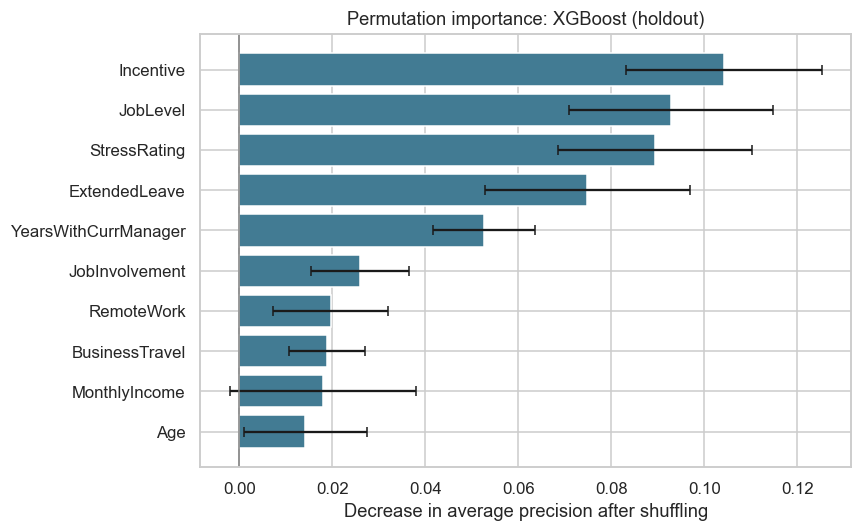

In [14]:
permutation = permutation_importance(
    best_model, X_test, y_test, scoring="average_precision",
    n_repeats=10, random_state=SEED, n_jobs=1,
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "mean_ap_decrease": permutation.importances_mean,
    "std_ap_decrease": permutation.importances_std,
}).sort_values("mean_ap_decrease", ascending=False)
display(importance.head(10).round(4))

top_features = importance.head(10).sort_values("mean_ap_decrease")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_features["feature"], top_features["mean_ap_decrease"],
        xerr=top_features["std_ap_decrease"], color="#427b93", capsize=3)
ax.axvline(0, color="grey", linewidth=1)
ax.set(xlabel="Decrease in average precision after shuffling",
       title=f"Permutation importance: {best_name} (holdout)")
fig.tight_layout()
fig.savefig(ASSETS / "feature-importance.png")
plt.show()

## 8. Conclusions and limitations

The results below are generated from this run so that the written summary
stays consistent with the tables.

In [15]:
final_metrics = evaluate_scores(y_test, test_probabilities, chosen_threshold)
display(Markdown(
    f"- **Selected model:** {best_name}, using mean development CV average precision.\n"
    f"- **Holdout ranking:** AP {final_metrics['average_precision']:.3f}; "
    f"ROC AUC {final_metrics['roc_auc']:.3f}.\n"
    f"- **Classification at threshold {chosen_threshold:.2f}:** "
    f"precision {final_metrics['precision']:.3f}, recall {final_metrics['recall']:.3f}, "
    f"F1 {final_metrics['f1']:.3f}.\n"
    f"- **Errors:** {fn} missed attrition cases and {fp} false alarms."
))

- **Selected model:** XGBoost, using mean development CV average precision.
- **Holdout ranking:** AP 0.579; ROC AUC 0.803.
- **Classification at threshold 0.30:** precision 0.629, recall 0.440, F1 0.518.
- **Errors:** 28 missed attrition cases and 13 false alarms.

This analysis can suggest questions to investigate, such as why particular job
groups have different observed attrition rates. It cannot establish that a
change in facilities, pay, or work arrangements will reduce attrition.

The main limitations are:

- The dataset is small and modified for teaching. Feature provenance, the
  meaning of the year labels, and the prediction horizon are not fully documented.
- Some features may have been recorded after the relevant outcome. A real
  application would require checking their availability at prediction time.
- One holdout year and five development folds provide limited evidence. Small
  score differences are not proof that one algorithm is generally superior.
- This is a revised analysis of data already examined in the original project.
  A genuinely new dataset is needed for independent confirmation.
- The scores are not calibrated, and the threshold optimises F1 rather than an
  observed intervention benefit. Group fairness and subgroup error rates have
  not been validated.

The next useful steps are to clarify the data definitions, repeat the analysis
on additional data, and evaluate an intervention separately from predicting
attrition. More complex models are not automatically the most useful next step.

## 9. Save results and check reproducibility

The exported tables and figures support the README. The checks below verify
that the final scaler was fitted on development data, that an unseen category
can be transformed, and that the source CSV has not changed.

In [16]:
engineered_train = add_features(X_train)
numeric_columns = engineered_train.select_dtypes(include=np.number).columns
numeric_pipeline = best_model.named_steps["preprocess"].named_transformers_["numeric"]
imputed_train = numeric_pipeline.named_steps["imputer"].transform(engineered_train[numeric_columns])
np.testing.assert_allclose(
    numeric_pipeline.named_steps["scaler"].mean_, imputed_train.mean(axis=0), rtol=1e-10
)
assert int(numeric_pipeline.named_steps["scaler"].n_samples_seen_) == len(X_train)

unseen_category = X_test.iloc[[0]].copy()
unseen_category["Department"] = "Previously unseen department"
assert np.isfinite(best_model.predict_proba(unseen_category)).all()
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == data_sha256

cv_results.to_csv(RESULTS / "cv_folds.csv", index=False)
cv_summary.to_csv(RESULTS / "cv_summary.csv")
threshold_results.to_csv(RESULTS / "thresholds.csv", index=False)
test_results.to_csv(RESULTS / "holdout_metrics.csv")
importance.to_csv(RESULTS / "permutation_importance.csv", index=False)

summary = {
    "dataset_sha256": data_sha256,
    "environment": environment,
    "seed": SEED,
    "rows": len(df),
    "columns": df.shape[1],
    "development_rows": len(development),
    "holdout_rows": len(holdout),
    "development_positives": int(y_train.sum()),
    "holdout_positives": int(y_test.sum()),
    "excluded_overlapping_rows": int(overlap.sum()),
    "excluded_predictors": excluded_columns,
    "selected_model": best_name,
    "selected_threshold": chosen_threshold,
    "holdout_metrics": {key: float(value) for key, value in final_metrics.items()},
    "confusion_matrix": {"tn": tn, "fp": fp, "fn": fn, "tp": tp},
}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print("Reproducibility checks passed. Tables saved to results/ and figures to assets/.")

Reproducibility checks passed. Tables saved to results/ and figures to assets/.


## References and assistance

- GCI Global 2025 course materials and supplied modified HR dataset,
  Matsuo-Iwasawa Laboratory, The University of Tokyo.
- scikit-learn: [common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html),
  [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html),
  and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [XGBoost Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html).

AI assistance was used in revising the code and explanations. The saved tables
and figures are produced by executing the notebook; they are not invented results.